<a href="https://colab.research.google.com/github/hend-22/-IT326-Project/blob/main/Reports/Phase3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Import Libraries & Load Preprocessed Dataset**

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics
from sklearn.metrics import confusion_matrix

url= "https://raw.githubusercontent.com/hend-22/-IT326-Project/main/Dataset/Preprocessed_dataset.csv"
df = pd.read_csv(url)
df.head()


,Age,Gender,Physical_Activity_Level,Diet_Type,BMI,Caffeine_Intake_mg,Water_Intake_liters,Screen_Time_Hours,Daily_Steps,Calories_Burned,Resting_Heart_Rate,Daily_Sleep_Hours,Deep_Sleep_Hours,Sleep_Quality_Score,Daily_Stress_Level
0,0.745098,0,0,2,0.370732,0.135616,0.244444,0.158333,0.166184,0.500415,0.533333,0.418919,0.296296,0.461538,0
1,1.000000,1,0,1,0.404878,0.142466,0.377778,0.158333,0.153223,0.367635,0.444444,0.608108,0.629630,0.661538,0
2,0.549020,1,0,1,0.317073,0.257534,0.200000,0.291667,0.179190,0.331120,0.488889,0.635135,0.444444,0.615385,1
3,0.274510,0,1,2,0.390244,0.169863,0.577778,0.650000,0.226360,0.494606,0.422222,0.527027,0.666667,0.446154,0
4,0.823529,1,1,0,0.370117,0.000000,0.422222,0.275000,0.279943,0.468880,0.511111,0.594595,0.555556,0.646154,0


## **Feature Selection**

In [57]:
fn = df.keys().tolist()[:-1]
X=df[fn]
y=df['Daily_Stress_Level']

## **Decision Tree Classification Using Entropy**

The Decision Tree classifier was applied to the dataset using the Entropy criterion (Information Gain) with three different train-test partitions:

70% Training  30% Testing

80% Training  20% Testing

90% Training  10% Testing


**Partition 70/30**

Accuracy: 0.674


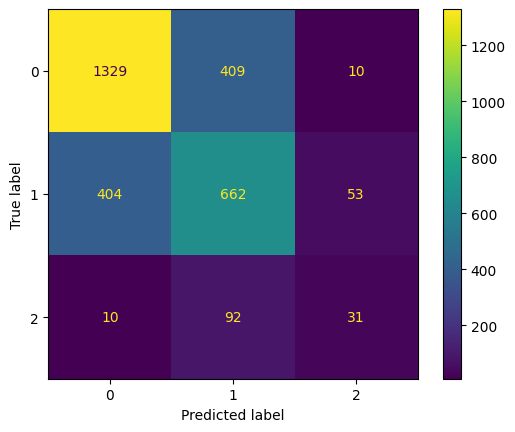

In [58]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=1)

clf=DecisionTreeClassifier(criterion="entropy")
clf=clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)

print("Accuracy:",metrics.accuracy_score(y_test, y_pred) )

cn=df['Daily_Stress_Level'].unique()
disp=ConfusionMatrixDisplay.from_estimator(clf,X_test,y_test,display_labels=cn)

**Partition 80/20**

Accuracy: 0.668


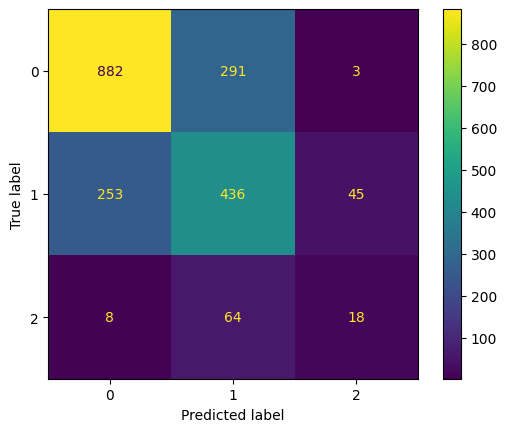

In [59]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=1)

clf=DecisionTreeClassifier(criterion="entropy")
clf=clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)

print("Accuracy:",metrics.accuracy_score(y_test, y_pred) )
cn=df['Daily_Stress_Level'].unique()
disp=ConfusionMatrixDisplay.from_estimator(clf,X_test,y_test,display_labels=cn)

**Partition 90/10**

Accuracy: 0.668


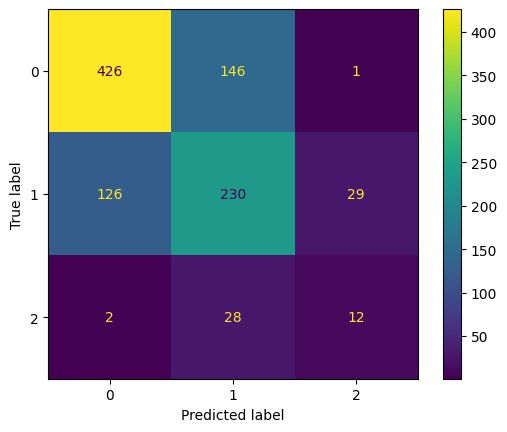

In [60]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.1,random_state=1)

clf=DecisionTreeClassifier(criterion="entropy")
clf=clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)

print("Accuracy:",metrics.accuracy_score(y_test, y_pred) )

cn=df['Daily_Stress_Level'].unique()
disp=ConfusionMatrixDisplay.from_estimator(clf,X_test,y_test,display_labels=cn)

## **Results Before Merging Classes**

**Partition	Accuracy**

70/30	      67.4%

80/20	      66.8%

90/10	      66.8%

**Results Discussion :**

Class 0 achieved the highest precision and recall values across all partitions. This indicates that the model was able to identify Class 0 more accurately than the other classes.

Class 2 achieved the lowest precision and recall values. This suggests that the classifier had difficulty recognizing instances of this class, which may be related to the imbalance in the dataset.

### **Class Merging**

To reduce class imbalance and simplify the classification task, Class 2 was merged with Class 1, converting the problem from a three-class classification task into a binary classification task.

In [62]:
df['Daily_Stress_Level'] = df['Daily_Stress_Level'].replace({2:1})
df['Daily_Stress_Level'].value_counts()

,count
Daily_Stress_Level,
0,5789
1,4211


In [63]:
fn = df.keys().tolist()[:-1]
X=df[fn]
y=df['Daily_Stress_Level']

## **Decision Tree Classification Using Entropy**

The Decision Tree classifier was applied to the dataset using the Entropy criterion (Information Gain) with three different train-test partitions:

70% Training  30% Testing

80% Training  20% Testing

90% Training  10% Testing

**Partition 70/30**

Accuracy: 0.7176666666666667


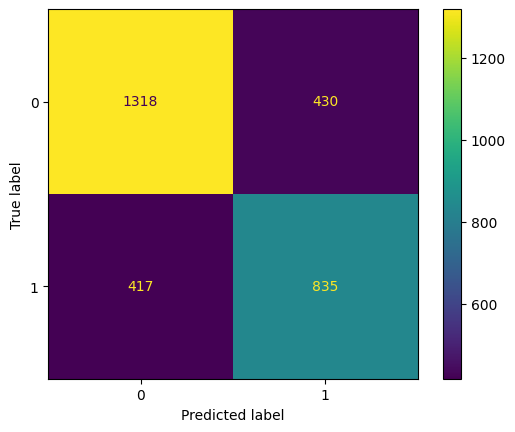

In [64]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=1)

clf=DecisionTreeClassifier(criterion="entropy")
clf=clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)

print("Accuracy:",metrics.accuracy_score(y_test, y_pred) )


cn=df['Daily_Stress_Level'].unique()
disp=ConfusionMatrixDisplay.from_estimator(clf,X_test,y_test,display_labels=cn)

**Partition 80/20**

Accuracy: 0.7245


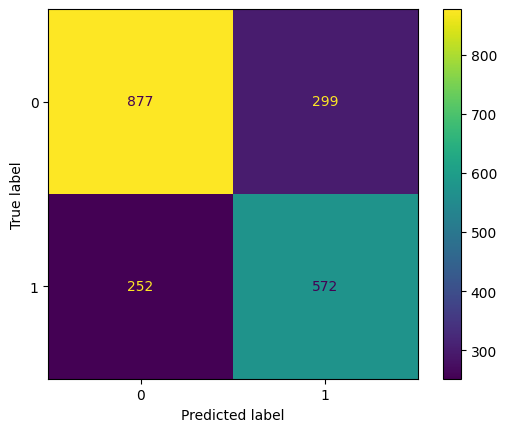

In [65]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=1)

clf=DecisionTreeClassifier(criterion="entropy")
clf=clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)

print("Accuracy:",metrics.accuracy_score(y_test, y_pred) )

cn=df['Daily_Stress_Level'].unique()
disp=ConfusionMatrixDisplay.from_estimator(clf,X_test,y_test,display_labels=cn)

**Partition 90/10**

Accuracy: 0.729


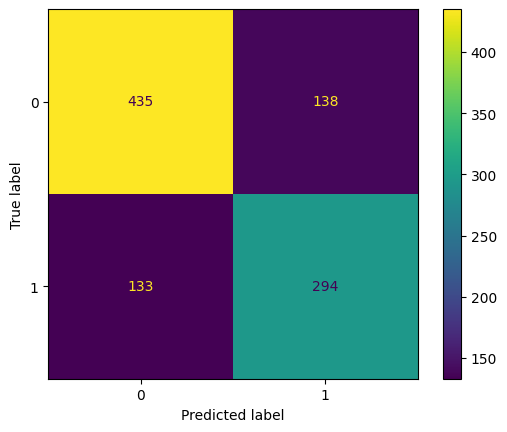

In [66]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.1,random_state=1)

clf=DecisionTreeClassifier(criterion="entropy")
clf=clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)

print("Accuracy:",metrics.accuracy_score(y_test, y_pred) )

cn=df['Daily_Stress_Level'].unique()
disp=ConfusionMatrixDisplay.from_estimator(clf,X_test,y_test,display_labels=cn)

## **Results After Merging Classes**


**Partition Accuracy**

70/30   71.77%

80/20   72.45%

90/10   72.90%

**Results Discussion :**

After merging Class 2 with Class 1, the Decision Tree classifier was trained again using the same partition sizes.



## **Comparison of Results**

Partition	Before Merging	After Merging

70/30	        67.4%	        71.77%

80/20	        66.8%	        72.45%

90/10	        66.8%	        72.90%

**Average Accuracy Before Merging:** 67.0%

**Average Accuracy After Merging:** 72.37%

**Improvement:** Approximately 5.37%

## **Analysis and Interpretation**
The results show a clear improvement in performance after merging Class 2 with Class 1.

The average accuracy increased from 67.0% to 72.37%, indicating that the classifier was able to build more effective decision rules after the merge.

This improvement suggests that reducing the number of classes helped the model learn clearer decision boundaries. Additionally, merging the classes reduced class imbalance and decreased model bias, allowing the classifier to make more accurate predictions.

The highest accuracy (72.90%) was achieved using the 90/10 partition, suggesting that providing more training data improved the model's learning capability and overall performance.

## **Visual Representation**

Confusion matrices were generated for each partition size to visually evaluate the classifier's performance and to examine the distribution of correct and incorrect predictions before and after class merging. These visualizations helped interpret the model's behavior and assess the effectiveness of the classification process.